# QC0426 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [2]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep

from hera.analysis import GateCalibration

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205
from drivers.async_station import async_station

In [3]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260619.3-QC0426'

# Connect Instruments

## Magnet

In [4]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.003 Tesla
Current:             : 0.019 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [5]:
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')  # <-- verify address
print(heater.sample_temperature())
print(heater.vaporizer_temperature())

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.14s
1.167
0.0


## Lock-ins

In [6]:
sr0 = SR830('sr0', "GPIB0::17::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [7]:
k_2400 = Keithley_2400('k_2400', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400.mode.set('VOLT')
k_2400.volt.set(0)
k_2400.rangei.set(1e-6)
k_2400.rangev.set(21)
k_2400.volt.step = 0.005
k_2400.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s


In [8]:
k_2410 = Keithley_2400('k_2410', 'GPIB0::25::INSTR')  # <-- verify address — Si-gate Keithley
k_2410.mode.set('VOLT')
k_2410.volt.set(0)
k_2410.rangei.set(1e-6)
k_2410.rangev.set(21)
k_2410.volt.step = 0.005
k_2410.volt.inter_delay = 0.01  # Si gate dV/dt pacing - dielectric safety
k_2410.nplci.set(1)

Connected to: KEITHLEY INSTRUMENTS INC. 2410 (serial:1293333, firmware:C30   Mar 17 2006 09:29:29/A02  /J/J) in 0.03s


## DC205 (top gate)

In [9]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — top-gate DC205
dc205.ramp_rate = 2  # V/s

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.04s


In [10]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). The dc205_volt
# wrapper is generic; the k_* role map is device-specific. Each value
# `# <-- validate`.

# Sweepable top-gate parameter — appears in the data as column 'DC_bias'.
def dcbias(vg):
    dc205.ramp_voltage(vg)

dc205_volt = qcodes.Parameter('DC_bias', unit='V', set_cmd=dcbias)

# Gate role aliases (recipes use k_tg / k_bg / k_si):
k_tg = dc205_volt   # top gate <- DC205 (fast axis is dc205_volt, NOT k_tg.volt)   # <-- validate
k_bg = k_2400       # back gate <- Keithley 2400                                     # <-- validate
k_si = k_2410       # Si gate   <- Keithley 2410                                     # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [11]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (dc205 / k_2400 / k_2410); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -6.0, +7.0    # top gate (dc205_volt), V    # <-- validate
BG_MIN, BG_MAX = -4.5, +4.5    # back gate (k_2400), V        # <-- validate
SI_MIN, SI_MAX = -50.0, +50.0  # Si gate (k_2410), V          # <-- validate
dc205_volt.vals = validators.Numbers(TG_MIN, TG_MAX)
dc205.voltage.vals = validators.Numbers(TG_MIN, TG_MAX)  # instrument-level: direct dc205 calls bypass dc205_volt
k_2400.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
k_2410.volt.vals = validators.Numbers(SI_MIN, SI_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.mag is a qcodes Parameter,
# so this validator rejects any magnet.mag(target) with |B| > B_SESSION_CAP
# before any hardware traffic. (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 8.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.mag.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — TYPO GUARD ONLY (sample_setpoint(3000) vs 300).
# The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 310.0  # K    # <-- verify
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)

# Helpers

In [12]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [13]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [14]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text.
meas_config = {
    "sr0": "drain current on B7",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "T3-T4 (Rxx)",  # <-- validate
    "sr2": "B4-B5 (Rxx)",  # <-- validate
    "sr3": "T5-B6 (Rxy, Hall)",  # <-- validate
    "bias_resistor": 100e6,
    "bias_voltage": sr1.amplitude(),
    "lockin_freq": sr1.frequency(),
    "sr0_sens": sr0.sensitivity(),
    "sr1_sens": sr1.sensitivity(),
    "sr2_sens": sr2.sensitivity(),
    "sr3_sens": sr3.sensitivity(),
    "sample_temperature:": heater.sample_temperature(),  # key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": k_2410.volt(),
    "comments": "<SET PER RUN>",
}

## QSwitch (contact mux) — LIVE

Contact-mux bring-up and the line/breakout maps are device-specific — from the
device card's Contact map section. `qsw.reset()` is **always forbidden** — it
opens the Si standing closures and drops the Si gate.

In [15]:
from drivers.QSwitch import QSwitch
from drivers.contact_mux import ContactMux

qsw = QSwitch('qswitch', 'ASRL4::INSTR')  # <-- verify address — QSwitch

# Contact label -> QSwitch line. Si standing-closure lines are EXCLUDED.
LINES = {  # <-- validate (from card contact map)
    "T1": 1,  "T2": 3,  "T3": 4,  "T4": 6,  "T5": 7,  "T6": 12, "T7": 13,
    "B1": 8,  "B2": 17, "B3": 23, "B4": 22, "B5": 20, "B6": 19, "B7": 18, "B8": 15,
}
# Instrument port -> front-panel BNC tap.
BREAKOUTS = {  # <-- validate (from card instrument taps)
    "source": 7, "drain": 8,
    "sr1+": 1, "sr1-": 2, "sr2+": 3, "sr2-": 4, "sr3+": 5, "sr3-": 6,
}
SETTLE_S = 4  # <-- validate (calibrated relay settle)

mux = ContactMux(qsw, lines=LINES, breakouts=BREAKOUTS, settle_s=SETTLE_S)
# qsw.reset() ALWAYS FORBIDDEN — drops the Si gate (standing closures).

Connected to: Quantum Machines QSwitch (serial:37, firmware:2.0) in 0.05s


# HERA — session start (2026-06-19)

In [16]:
print('hera-session: kernel bind ok')

hera-session: kernel bind ok


## HERA — E1 kernel-bind + VERIFY-completion probe (read-only)

**State: bring-up green, E0, awaiting the autonomy grant.** Gates A and B verified from disk:
all setup cells executed in one kernel (magnet status 0.003 T / PS on / output enabled;
sample_T 1.167 K; sr0-3 + QSwitch ser37 fw2.0 up); SAFETIES exec [11] commits exactly the
device-card limits - TG [-6, +7], BG [-4.5, +4.5], Si [-50, +50] V, B cap 8.0 T on
magnet.mag.vals. Within machine limits; no planned excursion enters the >10 T & >15 K zone.

This **read-only** cell is the brief's first-E1-execute kernel-bind probe. It (1) confirms this
kernel carries the operator's instruments, (2) finishes the VERIFY field/T reads with a fresh
magnet.mag() + sample_temperature(), (3) echoes the committed validators, and (4) records
lock-in tau/slope (rig card: operator-set, absent from run metadata - device card claims 0.3 s /
24 dB/oct -> 1.2 s/pt floor). No hardware writes, so it is safe to run in E0 now if you like.

**Next, on "go for autonomy":** Gate C - mux.select(...) to the provided contact config
(source T2 / drain B7 / sr1 T3-T4 / sr2 B4-B5 / sr3 T5-B6) + a cheap fixed-gate read to confirm
the contacts are live (first-session branch, no reference run) - then Step 1 of the
investigation: the 0 T TG-BG gate map for the CNP line and the (n, D) calibration.


In [17]:
# HERA E1 kernel-bind + VERIFY-completion probe — READ-ONLY (no hardware writes).
# Confirms this kernel carries the operator's instruments, finishes the session-start
# VERIFY field/T reads, echoes the committed SAFETIES validators, and records the
# lock-in tau/slope (rig card: operator-set, not in run metadata).
_g = globals()
print("=== namespace bind ===")
for _n in ("magnet", "heater", "sr0", "sr1", "sr2", "sr3", "k_2400", "k_2410",
           "dc205", "qsw", "mux", "dc205_volt", "k_tg", "k_bg", "k_si"):
    print(f"  {_n:11s} {type(_g[_n]).__name__ if _n in _g else 'MISSING'}")

print("=== magnet  (VERIFY: 0 T) ===")
print("  mag() =", magnet.mag(), " status field =", magnet._status()['field'])
print("  PS_on =", magnet.persistent_switch_on(), " output_enabled =", magnet.output_enabled())

print("=== thermometry  (VERIFY: base 1.2-1.3 K) ===")
print("  sample_T =", heater.sample_temperature(), " vaporizer_T =", heater.vaporizer_temperature())

print("=== SAFETIES validators  (echo committed ranges) ===")
print("  dc205_volt.vals =", dc205_volt.vals)
print("  k_2400.volt.vals =", k_2400.volt.vals, " (k_bg)")
print("  k_2410.volt.vals =", k_2410.volt.vals, " (k_si)")
print("  magnet.mag.vals  =", magnet.mag.vals)

print("=== lock-in settling  (tau / slope / sens) ===")
for _s in (sr0, sr1, sr2, sr3):
    print(f"  {_s.name}: tau={_s.time_constant()}  slope={_s.filter_slope()}  sens={_s.sensitivity()}")


=== namespace bind ===
  magnet      FastBi1K5
  heater      Lakeshore_335
  sr0         SR830
  sr1         SR830
  sr2         SR830
  sr3         SR830
  k_2400      Keithley_2400
  k_2410      Keithley_2400
  dc205       SRS_DC205
  qsw         QSwitch
  mux         ContactMux
  dc205_volt  Parameter
  k_tg        Parameter
  k_bg        Keithley_2400
  k_si        Keithley_2400
=== magnet  (VERIFY: 0 T) ===
  mag() = 0.0026170547945205476  status field = 0.002614671232876712
  PS_on = True  output_enabled = True
=== thermometry  (VERIFY: base 1.2-1.3 K) ===
  sample_T = 1.167  vaporizer_T = 0.0
=== SAFETIES validators  (echo committed ranges) ===
  dc205_volt.vals = <Numbers -6.0<=v<=7.0>
  k_2400.volt.vals = <Numbers -4.5<=v<=4.5>  (k_bg)
  k_2410.volt.vals = <Numbers -50.0<=v<=50.0>  (k_si)
  magnet.mag.vals  = <Numbers -8.0<=v<=8.0>
=== lock-in settling  (tau / slope / sens) ===
  sr0: tau=0.3  slope=24  sens=0.05
  sr1: tau=0.3  slope=24  sens=2e-05
  sr2: tau=0.3  slope=24  s

## HERA — Gate C: contact liveness on the provided config (E1 auto)

First-session re-entry baseline, first-session branch: no reference run to compare against,
so this is a liveness check, not a quantitative reproduction. Routes the device-card
**provided contact configuration** through the QSwitch (source T2 / drain B7 / sr1 T3-T4 /
sr2 B4-B5 / sr3 T5-B6 (Rxy)) and reads the lock-ins at the resting gate point (TG/BG/Si all
~0 V, B=0) to confirm source-drain carries current and each four-terminal pair reads a sane
resistance. All eight pads are in the device card's Alive set.

Preconditions asserted (cell assumes, does not set): sample_T < 5 K, |B| < 0.05 T, all three
gates inside their validators. `mux.select` is the Auto-bucket routing op (Si standing closures
16/11 excluded from the managed set; no `qsw.reset()`). No sweep, so no run dir — output is
inline. **Pass:** I_meas is finite (a few nA into the 100 MOhm-limited drive) and each Rxx reads
a finite, non-railed resistance. **Read-only on hardware apart from the relay routing.**


In [18]:
# Gate C — contact liveness on the provided configuration (first-session branch,
# no reference run). Routes the device-card config through the QSwitch, then reads
# the lock-ins at the resting gate point to confirm source-drain carries current
# and each four-terminal pair reads a sane resistance. No sweep -> no run dir.
import time

# --- preconditions this cell assumes but does not set ---
_T = heater.sample_temperature()
_B = magnet.mag()
_vtg = dc205.voltage(); _vbg = k_2400.volt(); _vsi = k_2410.volt()
print(f"[precond] sample_T={_T:.3f} K  B={_B:+.4f} T  TG={_vtg:+.3f} BG={_vbg:+.3f} Si={_vsi:+.3f} V")
assert _T < 5.0, f"sample_T {_T} K unexpectedly high"
assert abs(_B) < 0.05, f"|B|={_B} T not at zero"
assert -6.0 <= _vtg <= 7.0 and -4.5 <= _vbg <= 4.5 and -50 <= _vsi <= 50, "a gate sits outside its validator"

# --- route the provided contact configuration (Auto: ContactMux, in-envelope) ---
# Si standing closures (lines 16/11) are excluded from the managed set; select()
# never touches them and never calls qsw.reset().
mux.select({"source": "T2", "drain": "B7",
            "sr1+": "T3", "sr1-": "T4",
            "sr2+": "B4", "sr2-": "B5",
            "sr3+": "T5", "sr3-": "B6"})
print(f"[mux] selected provided config; settle_s={mux.settle_s}")
time.sleep(1.0)  # extra lock-in settle on top of mux settle (tau=0.3, 24 dB/oct)

# --- liveness read ---
I_bias_nom = sr1.amplitude() / 100e6                 # nominal drive current
I_meas = sr0.X() / abs(meas_config["sr0_gain"])      # measured AC current via Ithaco
print(f"[drive] V_ac={sr1.amplitude():.4f} V  f={sr1.frequency():.2f} Hz  I_bias_nom={I_bias_nom*1e9:.3f} nA")
print(f"[current] sr0.X={sr0.X():.4e} V_preamp -> I_meas={I_meas*1e9:.4f} nA  (P={sr0.P():.1f} deg)")
for nm, s in (("sr1 T3-T4", sr1), ("sr2 B4-B5", sr2), ("sr3 T5-B6 (Rxy)", sr3)):
    V = s.X()
    R = V / I_meas if I_meas != 0 else float('nan')
    print(f"[{nm:16s}] X={V:+.4e} V  P={s.P():+6.1f} deg  R=V/I_meas={R:10.1f} ohm")


[precond] sample_T=1.168 K  B=+0.0026 T  TG=+0.000 BG=+0.000 Si=+0.000 V


[mux] selected provided config; settle_s=4


[drive] V_ac=0.5000 V  f=13.00 Hz  I_bias_nom=5.000 nA
[current] sr0.X=-4.9935e-03 V_preamp -> I_meas=-4.9935 nA  (P=175.4 deg)
[sr1 T3-T4       ] X=+6.8583e-06 V  P=  -3.3 deg  R=V/I_meas=   -1373.5 ohm
[sr2 B4-B5       ] X=+6.1430e-06 V  P=  -3.2 deg  R=V/I_meas=   -1230.2 ohm
[sr3 T5-B6 (Rxy) ] X=+1.3635e-06 V  P=  -3.2 deg  R=V/I_meas=    -273.0 ohm


## HERA — Step 1a: 1D CNP locator (cheap-first, E1 auto)

`cnp-and-dline-calibration` Step 1 needs a 0 T gate map that brackets the CNP, but the
CNP location is not on record (established fresh this session) and at the origin the device
is metallic (~1.3 kOhm, Gate C). Rather than commit ~1 hr of 2D map against an unknown CNP
position, this **~2 min** 1D linecut sweeps TG across its full validator range [-6, +7] V at
**BG = 0, Si = 0, B = 0**: the Rxx maximum locates the CNP in V_tg at V_bg = 0 — i.e. the
CNP-line **intercept** — confirming the CNP is inside the gate box and centering/sizing the
2D map to follow. Geometry prior on the slope is dV_tg/dV_bg = -c_bg/c_tg ~ -1.3 (15.6 nm TG
hBN / 12 nm BG hBN), so a CNP at TG=b (BG=0) sweeps to b∓1.3·4.5 = b∓5.85 V across the BG
range — inside the [-6,7] TG window for |b| small.

Preconditions asserted: sample_T < 5 K, |B| < 0.05 T, and a live-current check (mux selection
persists from Gate C). dwell 1.0 s (tau=0.3, 24 dB/oct; under the 7-10·tau settling floor but
benign for locating a smooth Rxx peak — the fan/spot-check will sit at the floor). 106 pts,
0.123 V/pt. Tags `cnp-and-dline-calibration`. Writes `data/<id>/`.


[precond] sample_T=1.168 K  B=+0.0026 T
[precond] I_meas=-4.995 nA (expect ~few nA -> contacts live)
2026-06-19 20:42:47,723 [INFO] Ramping k_2400_volt: 0.0 -> 0.0


2026-06-19 20:42:47,796 [INFO] Ramping k_2410_volt: 0.0 -> 0.0


2026-06-19 20:42:47,801 [INFO] Ramping DC_bias: None -> -6.0


2026-06-19 20:42:52,850 [INFO] Starting sweep with ID 0


2026-06-19 20:42:52,851 [INFO] Minimum duration 0h 1m 46s


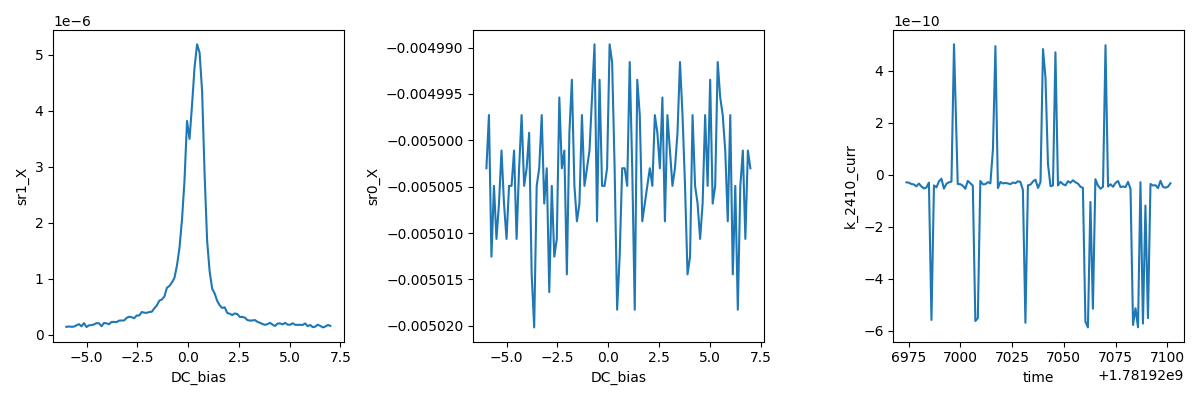

2026-06-19 20:45:02,339 [INFO] Completed in 0h 2m 8s


2026-06-19 20:45:02,340 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619.3-QC0426\data\0\data.tsv.gz


[done] CNP locator complete


In [19]:
# Step 1 (cheap-first) — 1D CNP locator: TG sweep across its full validator range
# at BG = 0, Si = 0, B = 0. The Rxx maximum locates the CNP in V_tg at V_bg = 0
# (the CNP-line intercept), confirming the CNP sits inside the gate box and sizing
# the 2D map. ~106 pts -> ~2 min. Tags cnp-and-dline-calibration.
import numpy as np, time

# --- preconditions (assumed, not set by this cell) ---
_T = heater.sample_temperature(); _B = magnet.mag()
print(f"[precond] sample_T={_T:.3f} K  B={_B:+.4f} T")
assert _T < 5.0, f"sample_T {_T} K too high"
assert abs(_B) < 0.05, f"|B|={_B} T not at zero"
# contacts still live? (mux selection persists from Gate C)
_I = sr0.X() / abs(meas_config["sr0_gain"])
print(f"[precond] I_meas={_I*1e9:.3f} nA (expect ~few nA -> contacts live)")
assert abs(_I) > 1e-10, "no current — contacts/mux lost?"

# --- station (fresh; comments per run) ---
meas_config["comments"] = "1D CNP locator: TG sweep [-6,7] V at BG=0, Si=0, B=0; provided config (src T2/drn B7, sr1 T3-T4, sr2 B4-B5, sr3 T5-B6)"
s = async_station(meas_config)
s.add_comment('cnp-and-dline-calibration')
s.add_comment(meas_config["comments"])

# followed params (raw; gain division is analysis-side from metadata)
s.fp(heater.sample_temperature)
s.fp(k_2400.curr).fp(k_2410.curr)                 # BG, Si leakage
for sx in (sr0, sr1, sr2, sr3):
    s.fp(sx.X).fp(sx.P)

# live plots: Rxx + current vs TG, Si leakage vs time
s.plot(dc205_volt, sr1.X); s.plot(dc205_volt, sr0.X); s.plot('time', k_2410.curr)

# --- position gates, then sweep TG ---
s.ramp(k_bg.volt, 0.0); s.ramp(k_si.volt, 0.0)
s.ramp(dc205_volt, -6.0); time.sleep(2)
tg_vec = np.linspace(-6.0, 7.0, 106)              # 0.123 V/pt
s.sweep(dc205_volt, tg_vec, delay=1.0)            # ~106 * ~1.2 s ~ 2 min
print("[done] CNP locator complete")


## HERA — Step 1b: 0 T TG-BG gate map (E1 auto, ~40 min)

`cnp-and-dline-calibration` Step 1 / `gatemap`. Axis-aligned megasweep in **raw gate volts**
(first map — cap ratio not yet trusted, so no (n,D) projection in the sweep): slow = **BG
[-4, 4] V x17 rows**, fast = **TG [-6, 7] V x105** (0.125 V), Si held at **0** (contact gate),
B = 0. Two deliverables: the **CNP ridge** V_tg(V_bg) -> slope = -c_bg/c_tg for the (n,D)
calibration, and the **metallic/insulating survey** across n at D~0 to pick fan contact pairs
that stay metallic (recipe Step 1).

Sizing from run 0: CNP intercept +0.44 V at BG=0, geometry slope prior -1.3 -> ridge
V_tg = -1.3·V_bg + 0.44 runs +5.64 .. -4.76 V across BG[-4,4], inside [-6,7] with >1 V margin
even at slope 1.5 (robust to slope uncertainty; BG capped at +-4, not +-4.5, to keep that margin).

**Cost:** run-0 calibrates 1.21 s/pt; 1785 pts + ~17 row-turnarounds ~= **40 min**. BG steps at
its 5 mV `volt.step` (graphite gate, safe); slow_delay 2 s. Leakage fp'd on both Keithleys (<1 nA
guard). **Checkpoint at ~row 5 (~12 min):** confirm a clean CNP ridge sits inside the TG window
(not edge-clipped), leakage <1 nA, lock-ins not railed -> continue / shift TG / abort. Preconditions
asserted (T<5 K, |B|<0.05 T, live current). Parks gates to 0 on completion. Tags `gatemap`.


In [20]:
# Step 1b — 0 T TG-BG gate map (gatemap.md / cnp-and-dline-calibration Step 1).
# Axis-aligned megasweep in raw gate volts (no cap-ratio assumed): slow = BG rows,
# fast = TG. CNP ridge V_tg(V_bg) -> slope = -c_bg/c_tg for the (n,D) calibration,
# plus the metallic/insulating survey for picking fan contact pairs. Si held at 0
# (contact gate). Sized from run-0: CNP intercept +0.44 V, prior slope -1.3.
import numpy as np, time

# --- preconditions (assumed, not set) ---
_T = heater.sample_temperature(); _B = magnet.mag()
print(f"[precond] sample_T={_T:.3f} K  B={_B:+.4f} T")
assert _T < 5.0 and abs(_B) < 0.05, "T/B precondition failed"
_I = sr0.X() / abs(meas_config["sr0_gain"])
print(f"[precond] I_meas={_I*1e9:.3f} nA")
assert abs(_I) > 1e-10, "no current — contacts/mux lost?"

# --- station (fresh; comments per run) ---
meas_config["comments"] = "0T gatemap: slow BG[-4,4] x17, fast TG[-6,7] x105, Si=0; CNP-line + metallic survey; provided config"
s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment(meas_config["comments"])
s.fp(heater.sample_temperature)
s.fp(k_2400.curr).fp(k_2410.curr)
for sx in (sr0, sr1, sr2, sr3):
    s.fp(sx.X).fp(sx.P)
# live leakage + a fast-row Rxx monitor (2D plot.png does not show the map; re-form from TSV)
s.plot('time', k_2400.curr); s.plot('time', k_2410.curr); s.plot(dc205_volt, sr1.X)

# --- position, then map ---
s.ramp(k_si.volt, 0.0)
s.ramp(k_bg.volt, -4.0); s.ramp(dc205_volt, -6.0); time.sleep(3)
bg_vec = np.linspace(-4.0, 4.0, 17)     # slow, 0.5 V rows
tg_vec = np.linspace(-6.0, 7.0, 105)    # fast, 0.125 V
s.megasweep(k_bg.volt, bg_vec, dc205_volt, tg_vec, slow_delay=2.0, fast_delay=1.0)
# park gates
k_bg.volt(0.0); dc205_volt(0.0)
print("[done] gatemap complete; gates parked at 0")


VisaIOError: ('VI_ERROR_TMO (-1073807339): Timeout expired before operation completed.', "asking 'KRDG? A' to <Lakeshore_335: l335_3>", 'getting l335_3_sample_temperature')

## HERA — post-abort state re-read (read-only)\nRun 1 (gate map) died on an LS335 per-point VISA timeout (rig-card dual-master quirk). The cell's gate-park line did not run, so gates are mid-position. Reading actual state before re-launching the corrected map.

In [26]:
# Post-abort state re-read (read-only). Run 1 (gate map) died on an LS335 per-point
# VISA timeout; the cell's gate-park line did not execute, so gates are mid-position.
print("sample_T =", heater.sample_temperature(), "K")     # single read (safe; not per-point)
print("B =", magnet.mag(), "T   PS_on =", magnet.persistent_switch_on())
print("TG (dc205.voltage) =", dc205.voltage(), "V")
print("BG (k_2400.volt)   =", k_2400.volt(), "V")
print("Si (k_2410.volt)   =", k_2410.volt(), "V")
_I = sr0.X() / abs(meas_config["sr0_gain"])
print("I_meas =", _I*1e9, "nA   (contacts live if ~few nA)")


sample_T = 1.159 K
B = 0.002614986301369863 T   PS_on = True
TG (dc205.voltage) = 0.0 V
BG (k_2400.volt)   = 0.0 V
Si (k_2410.volt)   = 0.0 V
I_meas = -19.9453 nA   (contacts live if ~few nA)


## HERA — Step 1b (v2): 0 T gate map, LS335 fp removed (E1 auto, ~40 min)\nv1 (cell 36) died on an LS335 per-point VISA timeout — `s.fp(heater.sample_temperature)` polls the Lakeshore every point, contending with the Grafana logger (rig-card dual-master quirk). **Fix:** drop the LS335 from fp; take one guarded `sample_temperature()` read at the top into the run comment; Grafana keeps the per-point T log. GPIB Keithley leakage channels stay fp'd (single-master, safe). Same map otherwise: slow BG[-4,4]x17, fast TG[-6,7]x105, Si=0. Re-positions gates from the current state (TG=7,BG=0 left by the abort). ~40 min; checkpoint at ~row 5. hera-watch armed on the next run.

[precond] sample_T=1.168 K  B=+0.0026 T
[precond] I_meas=-4.982 nA
2026-06-19 20:52:36,531 [INFO] Ramping k_2410_volt: 0.0 -> 0.0


2026-06-19 20:52:36,603 [INFO] Ramping k_2400_volt: 0.0 -> -4.0


2026-06-19 20:52:41,731 [INFO] Ramping DC_bias: 7.0 -> -6.0


2026-06-19 20:52:51,286 [INFO] Starting megasweep with ID 1


2026-06-19 20:52:51,287 [INFO] Minimum duration 0h 30m 19s


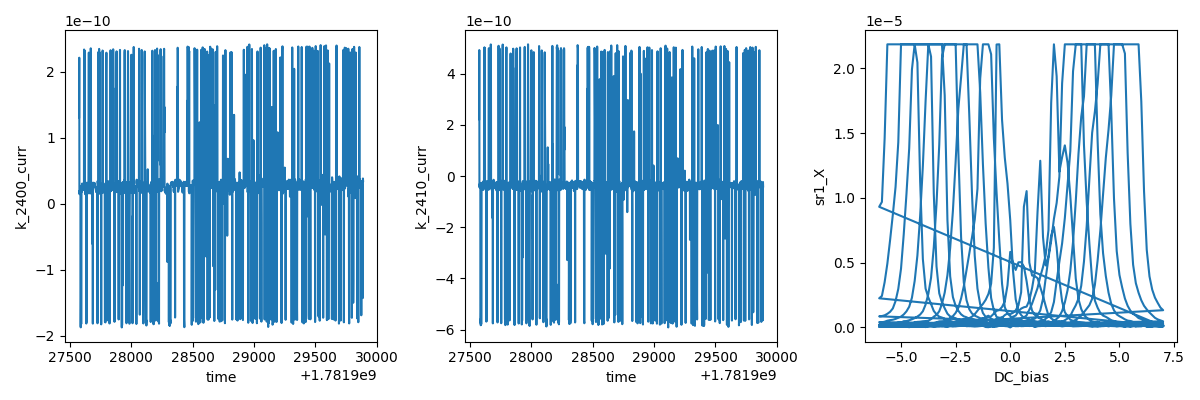

2026-06-19 21:31:29,114 [INFO] Completed in 0h 38m 37s


2026-06-19 21:31:29,115 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619.3-QC0426\data\1\data.tsv.gz


[done] gatemap v2 complete; gates parked at 0


In [22]:
# Step 1b (v2) — 0 T TG-BG gate map. FIX vs v1: do NOT fp the LS335 (per-point KRDG?
# contends with the Grafana logger -> VISA timeout, killed run 1, rig-card quirk).
# Temperature: one guarded read at the top into the comment; Grafana logs per-point T.
# GPIB Keithley leakage channels are single-master -> safe to fp per-point.
import numpy as np, time

# --- preconditions (assumed, not set) ---
try:
    _T = heater.sample_temperature()          # single read only (not per-point)
except Exception as e:
    _T = None; print("[warn] T read failed (LS335 busy):", e)
_B = magnet.mag()
print(f"[precond] sample_T={_T} K  B={_B:+.4f} T")
assert (_T is None) or _T < 5.0, "T precondition failed"
assert abs(_B) < 0.05, "B precondition failed"
_I = sr0.X() / abs(meas_config["sr0_gain"])
print(f"[precond] I_meas={_I*1e9:.3f} nA")
assert abs(_I) > 1e-10, "no current — contacts/mux lost?"

# --- station (fresh; comments per run; T snapshot in the comment, NOT fp'd) ---
meas_config["comments"] = f"0T gatemap v2: slow BG[-4,4] x17, fast TG[-6,7] x105, Si=0; T_start={_T} K; CNP-line + metallic survey; provided config (NO LS335 fp)"
s = async_station(meas_config)
s.add_comment('gatemap')
s.add_comment(meas_config["comments"])
s.fp(k_2400.curr).fp(k_2410.curr)             # BG, Si leakage (GPIB, safe per-point)
for sx in (sr0, sr1, sr2, sr3):
    s.fp(sx.X).fp(sx.P)
s.plot('time', k_2400.curr); s.plot('time', k_2410.curr); s.plot(dc205_volt, sr1.X)

# --- position from current state, then map ---
s.ramp(k_si.volt, 0.0)
s.ramp(k_bg.volt, -4.0); s.ramp(dc205_volt, -6.0); time.sleep(3)
bg_vec = np.linspace(-4.0, 4.0, 17)
tg_vec = np.linspace(-6.0, 7.0, 105)
s.megasweep(k_bg.volt, bg_vec, dc205_volt, tg_vec, slow_delay=2.0, fast_delay=1.0)
k_bg.volt(0.0); dc205_volt(0.0)
print("[done] gatemap v2 complete; gates parked at 0")


## HERA — Step 3a: SdH spot check, HOLE side (E1 auto, ~50 min)

`sdh-spot-check` / investigation Step 3. Fixed **(n = -5e12, D = 0)**, B swept **0 -> 4 T from
zero** (reads the onset directly). Gate point from the run-1 (n,D) calibration:
Vtg = -2.28 V, Vbg = -1.76 V (Si = 0), both well inside validators.

**Design.** High-|n| metallic regime -> **bias 2 V / 20 nA** (device card; the 0.5V/5nA default
would put the four-terminal signal near the ADC floor). Lock-in **dwell 2.2 s** = 7*tau at
tau=0.3/24 dB/oct (the settling floor — under-settling buries a small tone). **B-step 8 mT**:
Nyquist-resolves F_L = (h/4e)*n ~ 52 T at n=5e12 down to ~1 T (oscillation spacing in B at 1 T
~ B^2/F ~ 19 mT). Sensitivity set adaptively (~2x headroom) after settling at the gate point.
NO LS335 fp (the run-1 lesson). FFT read (1/B, MR background subtracted) happens post-run.

**Cost:** ~501 pts; magnet 8 mT/step blocking ramp (3.5 s) + 2.2 s dwell ~ 5.7 s/pt ->
**~48 min** + gate ramp. **Checkpoint at ~B=2 T (~25 min):** read the hera-watch digest for
visible SdH structure, leakage <1 nA, no sensitivity clipping -> continue / adjust. Leaves the
magnet at **4 T** for the electron-side spot check (4 -> 0 T descent — no wasted re-traverse).
hera-watch armed on the next run.


In [ ]:
# Step 3 — SdH spot check, HOLE side. Fixed (n=-5e12, D=0), B swept 0->4T from zero
# (reads the onset). High-|n| bias 2V/20nA; adaptive lock-in sensitivity (~2x headroom);
# dwell at the 7*tau settling floor (tau=0.3, 24 dB/oct). NO LS335 fp (rig-card quirk).
# Gate point from the device-card (n,D) calibration (GateCalibration / SI convention).
import numpy as np, time

# --- calibration (device card, run 1) ---
c_tg, c_bg, n_off = 1.7027e-3, 2.2004e-3, -1.581e15
E, EPS0 = 1.602176634e-19, 8.8541878128e-12
def gates_for(n, D=0.0):
    vtg = ((n-n_off)*E/2 + EPS0*D)/c_tg
    vbg = ((n-n_off)*E/2 - EPS0*D)/c_bg
    return vtg, vbg
n_target = -5e16                       # -5e12 cm^-2
Vtg, Vbg = gates_for(n_target, 0.0)
assert -6.0 <= Vtg <= 7.0 and -4.5 <= Vbg <= 4.5, f"gate point OOR: {Vtg},{Vbg}"

# --- preconditions ---
B0 = magnet.mag()
print(f"[precond] B={B0:+.4f} T (expect ~0)  target n=-5e12 D=0 -> Vtg={Vtg:.3f} Vbg={Vbg:.3f}")
assert abs(B0) < 0.05, "magnet not at ~0"
try: T0 = heater.sample_temperature()
except Exception as e: T0 = None; print("[warn] T read:", e)

# --- high-|n| bias 2V/20nA (sr1 is the AC source) ---
sr1.amplitude(2.0); meas_config["bias_voltage"] = sr1.amplitude()
print(f"[bias] V_ac={sr1.amplitude()} V -> ~{sr1.amplitude()/100e6*1e9:.0f} nA")

# --- station + fp (no LS335) ---
meas_config["comments"] = f"sdh-spot-check HOLE n=-5e12 D=0 (Vtg={Vtg:.3f},Vbg={Vbg:.3f}); B 0->4T 8mT; bias 2V/20nA; T_start={T0}"
s = async_station(meas_config)
s.add_comment('sdh-spot-check'); s.add_comment(meas_config["comments"])
s.fp(k_2400.curr).fp(k_2410.curr)
for sx in (sr0, sr1, sr2, sr3): s.fp(sx.X).fp(sx.P)
s.plot(magnet.mag, sr1.X); s.plot(magnet.mag, sr2.X); s.plot('time', k_2410.curr)

# --- position gates, settle, set sensitivity ---
s.ramp(k_si.volt, 0.0); s.ramp(k_bg.volt, Vbg); s.ramp(dc205_volt, Vtg); time.sleep(5)
SENS=[2e-9,5e-9,1e-8,2e-8,5e-8,1e-7,2e-7,5e-7,1e-6,2e-6,5e-6,1e-5,2e-5,5e-5,1e-4,2e-4,5e-4,1e-3,2e-3,5e-3,1e-2,2e-2,5e-2,1e-1,2e-1,5e-1,1.0]
Im = sr0.X()/abs(meas_config["sr0_gain"])
print(f"[settle] I_meas={Im*1e9:.2f} nA  R_sr1={abs(sr1.X()/Im):.0f} R_sr2={abs(sr2.X()/Im):.0f} ohm")
for sx in (sr1, sr2, sr3):
    x = abs(sx.X()); pick = next((v for v in SENS if v >= 2.2*max(x,1e-9)), 1.0)
    sx.sensitivity(pick); print(f"   {sx.name}: |X|={x:.2e} -> sens {pick:.0e}")
meas_config["sr1_sens"]=sr1.sensitivity(); meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
time.sleep(2)

# --- field sweep 0 -> 4 T, 8 mT step, dwell 2.2 s (7*tau floor) ---
field_vec = np.linspace(0.0, 4.0, 501)
s.sweep(magnet.mag, field_vec, delay=2.2)
print("[done] SdH spot check HOLE complete; B left at 4 T for the electron-side descent")


[precond] B=+0.0026 T (expect ~0)  target n=-5e12 D=0 -> Vtg=-2.278 Vbg=-1.763
[bias] V_ac=2.0 V -> ~20 nA
2026-06-19 21:44:31,707 [INFO] Ramping k_2410_volt: 0.0 -> 0.0


2026-06-19 21:44:31,778 [INFO] Ramping k_2400_volt: 0.0 -> -1.7627656435567625


2026-06-19 21:44:34,036 [INFO] Ramping DC_bias: 0.0 -> -2.278022859037


[settle] I_meas=-19.99 nA  R_sr1=40 R_sr2=37 ohm
   sr1: |X|=7.91e-07 -> sens 2e-06
   sr2: |X|=7.36e-07 -> sens 2e-06
   sr3: |X|=7.45e-09 -> sens 2e-08


2026-06-19 21:44:42,658 [INFO] Starting sweep with ID 2


2026-06-19 21:44:42,659 [INFO] Minimum duration 0h 18m 22s


## HERA — Step 3b: SdH spot check, ELECTRON side (E1 auto, ~74 min)

`sdh-spot-check` / investigation Step 3, clean run. Fixed **(n = +5e12, D = 0)** (Vtg = +2.43,
Vbg = +1.88), B swept **4 -> 0 T** — descends, riding the magnet home from the hole spot check
(no wasted re-traverse); onset read at the low end.

**Clean-acquisition fixes from run 2 (hole):** FIXED sensitivities sized for the HIGH field so
nothing clips over 0-4 T — sr1/sr2 = 1e-5 (covers ~500 Ω), sr3 = 2e-5 (covers the ~500 Ω
classical Hall at 4 T, which clipped on the hole run). bias 2 V/20 nA, dwell 2.2 s (7*tau).
NO LS335 fp. **FFT window [1, 4] T** — alias-free (8 mT Nyquist at 1 T ~ 62 T > F_L = 52 T; the
hole run's <1 T data under-sampled F_L). Full unclipped [1,4] T gives ~30 periods, delta(1/B) =
0.75, deltaF ~ 1.3 T.

**Why this matters:** the hole run (run 2) hinted at an ABA-like pair (~8.5 T dominant + ~44 T,
summing to F_L) but was clipped at 2.3 T and partly aliased -> suggestive, not decisive. A clean
electron-side spot check tests whether the same partition appears (per-channel, per the FS-count
combinatorics) and which side gives cleaner SdH for the fan.

**Cost** ~74 min (8.7 s/pt). **Checkpoint at ~B=2.5 T (~30 min):** SdH visible, no clipping,
leakage <1 nA. Ends with the **magnet at 0 T**. hera-watch armed on the next run.


[precond] B=+4.0026 T (expect ~4)  target n=+5e12 D=0 -> Vtg=2.427 Vbg=1.878
2026-06-19 23:03:28,144 [INFO] Ramping k_2410_volt: 0.0 -> 0.0


2026-06-19 23:03:28,205 [INFO] Ramping k_2400_volt: -1.763 -> 1.8778829521531084


2026-06-19 23:03:32,842 [INFO] Ramping DC_bias: -2.278022859037 -> 2.426789010346919


[settle@4T] I=-19.91 nA  R_sr1=156 R_sr2=107 Rxy_sr3=379 Ω


2026-06-19 23:03:42,652 [INFO] Starting sweep with ID 3


2026-06-19 23:03:42,654 [INFO] Minimum duration 0h 18m 22s


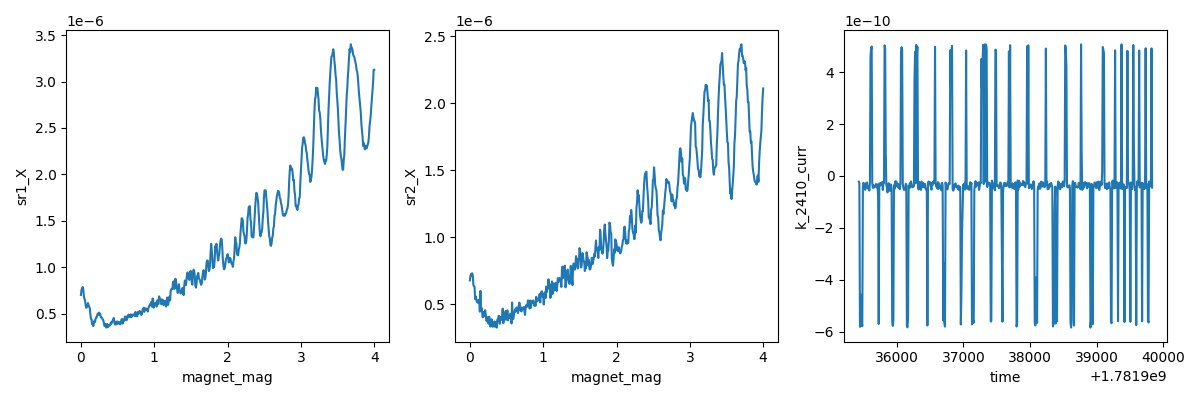

2026-06-20 00:17:15,162 [INFO] Completed in 1h 13m 31s


2026-06-20 00:17:15,164 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260619.3-QC0426\data\3\data.tsv.gz


[done] SdH spot check ELECTRON complete; magnet home at 0 T


In [24]:
# Step 3b — SdH spot check, ELECTRON side. Fixed (n=+5e12, D=0), B swept 4->0 T
# (descend, ride the magnet home from the hole spot check; onset read at the low end).
# CLEAN acquisition: FIXED high-field-sized sensitivities so nothing clips over 0-4 T
# (hole-side lesson: sr1/sr2 clipped at 2e-6/109Ω, sr3 clipped on the classical Hall).
# bias 2V/20nA; dwell 2.2 s (7*tau). NO LS335 fp. FFT window will be [1,4] T (alias-free:
# 8 mT Nyquist at 1 T ~ 62 T > F_L 52 T; below 1 T the step under-samples F_L).
import numpy as np, time

c_tg, c_bg, n_off = 1.7027e-3, 2.2004e-3, -1.581e15
E, EPS0 = 1.602176634e-19, 8.8541878128e-12
def gates_for(n, D=0.0):
    return ((n-n_off)*E/2 + EPS0*D)/c_tg, ((n-n_off)*E/2 - EPS0*D)/c_bg
n_target = +5e16
Vtg, Vbg = gates_for(n_target, 0.0)
assert -6.0 <= Vtg <= 7.0 and -4.5 <= Vbg <= 4.5, f"gate OOR {Vtg},{Vbg}"

B0 = magnet.mag()
print(f"[precond] B={B0:+.4f} T (expect ~4)  target n=+5e12 D=0 -> Vtg={Vtg:.3f} Vbg={Vbg:.3f}")
assert abs(B0-4.0) < 0.2, "magnet not at ~4 T (hole spot check should have left it there)"
try: T0 = heater.sample_temperature()
except Exception as e: T0 = None; print("[warn] T:", e)

sr1.amplitude(2.0); meas_config["bias_voltage"] = sr1.amplitude()
meas_config["comments"] = f"sdh-spot-check ELECTRON n=+5e12 D=0 (Vtg={Vtg:.3f},Vbg={Vbg:.3f}); B 4->0T 8mT; bias 2V/20nA; fixed sens sr1/2=1e-5 sr3=2e-5; T_start={T0}"
s = async_station(meas_config)
s.add_comment('sdh-spot-check'); s.add_comment(meas_config["comments"])
s.fp(k_2400.curr).fp(k_2410.curr)
for sx in (sr0, sr1, sr2, sr3): s.fp(sx.X).fp(sx.P)
s.plot(magnet.mag, sr1.X); s.plot(magnet.mag, sr2.X); s.plot('time', k_2410.curr)

# position gates (at 4 T — fine), settle, set FIXED high-field sensitivities
s.ramp(k_si.volt, 0.0); s.ramp(k_bg.volt, Vbg); s.ramp(dc205_volt, Vtg); time.sleep(5)
sr1.sensitivity(1e-5); sr2.sensitivity(1e-5); sr3.sensitivity(2e-5)
meas_config["sr1_sens"]=sr1.sensitivity(); meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
Im = sr0.X()/abs(meas_config["sr0_gain"])
print(f"[settle@4T] I={Im*1e9:.2f} nA  R_sr1={abs(sr1.X()/Im):.0f} R_sr2={abs(sr2.X()/Im):.0f} Rxy_sr3={abs(sr3.X()/Im):.0f} Ω")
time.sleep(2)

field_vec = np.linspace(4.0, 0.0, 501)   # descend
s.sweep(magnet.mag, field_vec, delay=2.2)
print("[done] SdH spot check ELECTRON complete; magnet home at 0 T")


## HERA — Step 4: Landau fan, ELECTRON side D=0 (E1 auto, ~8 h)

`landau-fan-vti` / investigation Step 4. The electron side (run 3) gave the clean,
low-onset (~0.4 T) SdH with a reproduced two-pocket structure -> take the fan here.
Field = **slow** axis (magnet ramps once, monotonically 0.4 -> 4.0 T); paired-gate
**n-line at D=0** = fast axis, via the run-1 calibration.

**Design / Nyquist.** n = 1.0 .. 4.5e12 (41 pts): spans the model-overlay range (<=3.5e12,
for ML/BL Onsager labeling, Step 5) up to high-n where the ~8 T ML partner is resolvable.
B = 0.4 .. 4.0 T, **8 mT** (451 rows): per-column FFT window [1,4] T is alias-free (8 mT
Nyquist at 1 T ~ 62 T > F_L) and Nyquist-resolves the B-period down to n~4.5e12 (>=2 rows/period
at B>=1 T) -- measurement-dominated regime, so n_max capped at 4.5e12 rather than coarsening B
(per the -vti cost note). **fast_delay 1.0 s** (~3 tau): a deliberate amplitude-for-time trade --
under-settling attenuates SdH *amplitude* but not *frequency* (the FS-count observable); the
spot checks (runs 2-3, full 2.2 s settling) hold the amplitude reference. Fixed sensitivities
sr1/sr2=1e-5, sr3=2e-5 (no autorange -> row-to-row comparability); the lowest-n columns may clip
near the high-B CNP corner (overlay anchors, not the count target) -- flagged.

**Cost** ~8 h (min-duration 5.3 h delays + ~2.6 h measure overhead + magnet stepping); ETA ~08:50.
NO LS335 fp. **Checkpoint at ~B=1.5 T (~30%, ~2.5 h):** re-form 3-4 n-columns, FFT, confirm the
two-pocket structure tracks F(n) and leakage <1 nA -> continue / adjust / abandon. Ends with gates
parked at 0 and the magnet ramped to 0. hera-watch armed; client timeout set well above 8 h.


In [ ]:
# Step 4 — Landau fan, ELECTRON side at D=0 (the cleaner side, run 3). Field = SLOW axis
# (magnet ramps once, monotonically), paired-gate n-line = FAST axis. FS-count via per-column
# 1/B FFT of F(n): tracks the ML+BL partition f_ML(n)+f_BL(n)=F_L(n) and feeds the Onsager
# overlay (valid n<=3.5e12). NO LS335 fp.
import numpy as np, time

c_tg, c_bg, n_off = 1.7027e-3, 2.2004e-3, -1.581e15
E, EPS0 = 1.602176634e-19, 8.8541878128e-12
def gates_for(n, D=0.0):
    return ((n-n_off)*E/2 + EPS0*D)/c_tg, ((n-n_off)*E/2 - EPS0*D)/c_bg

# fast axis: n-line at D=0, low->high electron density
ns = np.linspace(1.0e16, 4.5e16, 41)            # 1.0 .. 4.5 e12 cm^-2
Vtgs, Vbgs = gates_for(ns, 0.0)
assert Vtgs.min()>=-6 and Vtgs.max()<=7 and Vbgs.min()>=-4.5 and Vbgs.max()<=4.5, "n-line OOR"
# slow axis: field, ascending, 8 mT step
B_vec = np.linspace(0.4, 4.0, 451)              # 8 mT; per-column FFT window [1,4] T alias-free
print(f"fan: {len(B_vec)} B-rows x {len(ns)} n-pts; n {ns.min()/1e16:.1f}..{ns.max()/1e16:.1f} e12; "
      f"Vtg {Vtgs.min():.2f}..{Vtgs.max():.2f}  Vbg {Vbgs.min():.2f}..{Vbgs.max():.2f}")

# --- preconditions ---
B0 = magnet.mag(); print(f"[precond] B={B0:+.4f} T (expect ~0)")
assert abs(B0) < 0.1, "magnet not near 0"
try: T0 = heater.sample_temperature()
except Exception as e: T0=None; print("[warn] T:",e)
sr1.amplitude(2.0)                              # bias 2V/20nA

# --- station ---
meas_config["bias_voltage"]=sr1.amplitude()
meas_config["comments"]=f"landau-fan-vti ELECTRON D=0, n=1.0..4.5e12 (41), B=0.4..4.0T (451, 8mT), bias 2V/20nA, fast_delay 1.0s; T_start={T0}"
s = async_station(meas_config)
s.add_comment('landau-fan-vti'); s.add_comment(meas_config["comments"])
s.fp(k_2400.curr).fp(k_2410.curr)
for sx in (sr0, sr1, sr2, sr3): s.fp(sx.X).fp(sx.P)
s.plot('time', k_2400.curr); s.plot('time', k_2410.curr); s.plot(magnet.mag, sr1.X)

# --- position: gates to first n-point, magnet to B_start, settle; fixed high-field sens ---
s.ramp(k_si.volt, 0.0); s.ramp(dc205_volt, Vtgs[0]); s.ramp(k_bg.volt, Vbgs[0])
s.ramp(magnet.mag, B_vec[0]); time.sleep(5)
sr1.sensitivity(1e-5); sr2.sensitivity(1e-5); sr3.sensitivity(2e-5)
meas_config["sr1_sens"]=sr1.sensitivity(); meas_config["sr2_sens"]=sr2.sensitivity(); meas_config["sr3_sens"]=sr3.sensitivity()
time.sleep(2)

# --- the fan ---
s.multimegasweep([magnet.mag], [B_vec], [dc205_volt, k_bg.volt], [Vtgs, Vbgs],
                 slow_delay=1.0, fast_delay=1.0)
# park
k_bg.volt(0.0); dc205_volt(0.0); magnet.mag(0.0)
print("[done] electron fan complete; gates 0, magnet ramping to 0")


fan: 451 B-rows x 41 n-pts; n 1.0..4.5 e12; Vtg 0.54..2.19  Vbg 0.42..1.70
[precond] B=+0.0026 T (expect ~0)
2026-06-20 00:23:19,301 [INFO] Ramping k_2410_volt: 0.0 -> 0.0


2026-06-20 00:23:19,303 [INFO] Ramping DC_bias: 2.426789010346919 -> 0.5448642625933517


2026-06-20 00:23:20,356 [INFO] Ramping k_2400_volt: 1.878 -> 0.42162351386916014


2026-06-20 00:23:22,198 [INFO] Ramping magnet_mag: 0.0026082602739726027 -> 0.4


2026-06-20 00:26:27,825 [INFO] Starting multimegasweep with ID 4


2026-06-20 00:26:27,826 [INFO] Minimum duration 5h 15m 42s


## HERA — closeout: restore session-start instrument settings (operator request)
Bias drive back to 0.5 V / 5 nA (was 2 V / 20 nA for high-|n| SdH); lock-in sensitivities back to start (sr0 0.05, sr1/sr2 2e-5, sr3 1e-4); gates re-asserted at 0; field already 0. Time constants (0.3 s / 24 dB) were never changed. QSwitch left at the provided contact config (the blessed routing; `qsw.reset()` forbidden — Si standing closures 16/11 stay).

In [27]:
# Closeout — restore instruments/device to session-start settings (operator request).
# Start state (from the bind probe, cell 30, and Gate C): bias 0.5 V; sens sr0=0.05,
# sr1=2e-5, sr2=2e-5, sr3=1e-4; tau=0.3/24dB (untouched); gates 0; B=0.
# Bias drive back to the 0.5 V / 5 nA default (was 2.0 V / 20 nA for high-|n| work)
sr1.amplitude(0.5)
# Lock-in sensitivities back to session-start
sr0.sensitivity(0.05)
sr1.sensitivity(2e-5)
sr2.sensitivity(2e-5)
sr3.sensitivity(1e-4)
# Re-assert gates parked at 0 (already there) and confirm field at 0 (PS on)
k_si.volt(0.0); k_2400.volt(0.0); dc205.ramp_voltage(0.0)

# --- confirm ---
print("bias sr1.amplitude =", sr1.amplitude(), "V  (~%.0f nA)" % (sr1.amplitude()/100e6*1e9))
for s in (sr0, sr1, sr2, sr3):
    print(f"  {s.name}: sens={s.sensitivity():.0e}  tau={s.time_constant()}  slope={s.filter_slope()}")
print("TG=%.3f BG=%.3f Si=%.3f V   B=%.4f T  PS_on=%s" % (
    dc205.voltage(), k_2400.volt(), k_2410.volt(), magnet.mag(), magnet.persistent_switch_on()))
print("sample_T =", heater.sample_temperature(), "K")


bias sr1.amplitude = 0.5 V  (~5 nA)
  sr0: sens=5e-02  tau=0.3  slope=24
  sr1: sens=2e-05  tau=0.3  slope=24
  sr2: sens=2e-05  tau=0.3  slope=24
  sr3: sens=1e-04  tau=0.3  slope=24


TG=0.000 BG=0.000 Si=0.000 V   B=0.0026 T  PS_on=True
sample_T = 1.157 K
